# Prerequisite 05B · 神经网络从零开始

[上一章：机器学习基础](Prerequisite05_Machine_Learning.ipynb) · [预备篇导航](Prerequisite00_Index.ipynb) · [下一章：PyTorch](Prerequisite06_PyTorch.ipynb)

**为什么要“手写一次”：**原书第 3 章只用很短篇幅介绍 PyTorch，第 6 章就开始用卷积网络玩 Atari。
如果没亲手写过一次前向和反向传播，`loss.backward()` 就是黑盒，DQN 不收敛时你很难判断问题在哪。

本课只用 NumPy，从“线性模型做不到什么”出发，写出一个两层网络并训练它解决 XOR。

**学完你应该能：**

- 说清神经元、权重、偏置、激活函数、前向传播、反向传播分别是什么；
- 在纸上写出每一层的 shape；
- 用链式法则推出两层网络的梯度，并用数值梯度验证；
- 解释 DQN 中“Q 网络”与 Q 表的关系。

建议时长：4–6 小时。


## 1. 线性模型的天花板：XOR

XOR（异或）：两个输入相同输出 0，不同输出 1。把四个点画出来，你会发现**任何一条直线都无法把两类分开**。
线性模型（包括逻辑回归）只能画直线，所以注定失败。


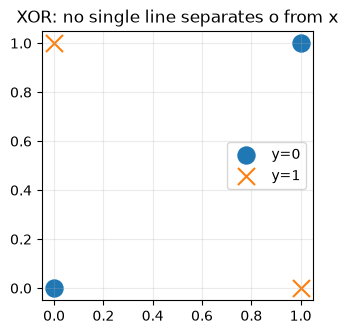

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y = np.array([[0.], [1.], [1.], [0.]])

plt.figure(figsize=(3.5, 3.5))
for label, marker in ((0, "o"), (1, "x")):
    mask = y[:, 0] == label
    plt.scatter(X[mask, 0], X[mask, 1], s=150, marker=marker, label=f"y={label}")
plt.title("XOR: no single line separates o from x")
plt.legend(); plt.grid(alpha=.25); plt.show(); plt.close()


## 2. 神经元、层与激活函数

一个**神经元**：输入加权求和、加偏置，再过一个非线性函数 $h=\phi(xw+b)$。
一**层**就是很多神经元并排，用矩阵一次算完：$H=\phi(XW+b)$。

| 激活函数 | 公式 | 常见位置 |
|---|---|---|
| ReLU | $\max(0,z)$ | 隐藏层（DQN、PPO 默认） |
| tanh | $\tanh z\in(-1,1)$ | 小网络隐藏层；连续动作输出缩放 |
| sigmoid | $1/(1+e^{-z})\in(0,1)$ | 二分类输出概率 |
| （无） | $z$ | Q 值输出、回归输出 |

**为什么一定要非线性：**两层线性层相乘仍是一层线性层（本课练习 5 会证明）。加了激活函数，网络才能“折弯”决策边界。


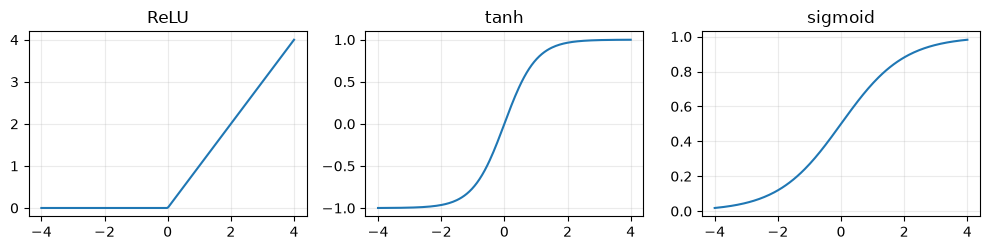

In [2]:
z = np.linspace(-4, 4, 200)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for ax, (name, values) in zip(axes, [("ReLU", np.maximum(z, 0)), ("tanh", np.tanh(z)), ("sigmoid", 1 / (1 + np.exp(-z)))]):
    ax.plot(z, values); ax.set_title(name); ax.grid(alpha=.25)
plt.tight_layout(); plt.show(); plt.close()


## 3. 前向传播：先把 shape 写在纸上

网络结构 `2 → 8 → 1`（输入 2 维，隐藏层 8 个神经元，输出 1 个概率）：

| 步骤 | 计算 | shape（batch=B=4） |
|---|---|---|
| 输入 | $X$ | `(4, 2)` |
| 隐藏层预激活 | $Z_1=XW_1+b_1$ | `(4,2)@(2,8)+(8,) → (4, 8)` |
| 隐藏层输出 | $H=\tanh(Z_1)$ | `(4, 8)` |
| 输出预激活 | $Z_2=HW_2+b_2$ | `(4,8)@(8,1)+(1,) → (4, 1)` |
| 预测概率 | $\hat y=\sigma(Z_2)$ | `(4, 1)` |
| 损失 | $L=\mathrm{BCE}(\hat y, y)$ | 标量 |


In [3]:
rng = np.random.default_rng(3)
hidden = 8
params = {
    "W1": rng.normal(0, 1.0, size=(2, hidden)), "b1": np.zeros(hidden),
    "W2": rng.normal(0, 1.0, size=(hidden, 1)), "b2": np.zeros(1),
}

def forward(params, X):
    Z1 = X @ params["W1"] + params["b1"]
    H = np.tanh(Z1)
    Z2 = H @ params["W2"] + params["b2"]
    y_hat = 1 / (1 + np.exp(-Z2))
    cache = {"X": X, "H": H, "y_hat": y_hat}   # 反向传播要用到的中间结果
    return y_hat, cache

def bce_loss(y_hat, y):
    y_hat = np.clip(y_hat, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat)))

y_hat, cache = forward(params, X)
print("预测 shape:", y_hat.shape, " 初始 loss:", round(bce_loss(y_hat, y), 4))


预测 shape: (4, 1)  初始 loss: 0.8362


## 4. 反向传播：链式法则一层层往回传

目标：求 $\partial L/\partial W_1$ 等四个梯度。sigmoid 配 BCE 有一个很好用的结果：
$$\frac{\partial L}{\partial Z_2}=\frac{\hat y-y}{B}$$
之后每一步都是“上游梯度 × 本层局部导数”：

| 梯度 | 公式 | shape |
|---|---|---|
| $dZ_2$ | $(\hat y-y)/B$ | `(4,1)` |
| $dW_2$ | $H^\top dZ_2$ | `(8,4)@(4,1) → (8,1)` |
| $db_2$ | $dZ_2$ 按 batch 求和 | `(1,)` |
| $dH$ | $dZ_2 W_2^\top$ | `(4,1)@(1,8) → (4,8)` |
| $dZ_1$ | $dH\odot(1-H^2)$ | `(4,8)`（$\tanh'=1-\tanh^2$） |
| $dW_1$ | $X^\top dZ_1$ | `(2,4)@(4,8) → (2,8)` |
| $db_1$ | $dZ_1$ 按 batch 求和 | `(8,)` |

**规律：**每个参数梯度的 shape 一定和参数本身相同。shape 对不上，公式就一定错了。


In [4]:
def backward(params, cache, y):
    X, H, y_hat = cache["X"], cache["H"], cache["y_hat"]
    B = X.shape[0]
    dZ2 = (y_hat - y) / B
    grads = {"W2": H.T @ dZ2, "b2": dZ2.sum(axis=0)}
    dH = dZ2 @ params["W2"].T
    dZ1 = dH * (1 - H ** 2)
    grads["W1"] = X.T @ dZ1
    grads["b1"] = dZ1.sum(axis=0)
    return grads

# 梯度检查：随机挑几个参数元素，用数值差分核对解析梯度
grads = backward(params, cache, y)
eps = 1e-5
for name in ("W1", "W2"):
    index = (0, 0)
    original = params[name][index]
    params[name][index] = original + eps; plus = bce_loss(forward(params, X)[0], y)
    params[name][index] = original - eps; minus = bce_loss(forward(params, X)[0], y)
    params[name][index] = original
    numeric = (plus - minus) / (2 * eps)
    print(f"{name}{index}: 解析 {grads[name][index]:+.6f}  数值 {numeric:+.6f}")
    assert abs(numeric - grads[name][index]) < 1e-6
print("梯度检查通过")


W1(0, 0): 解析 +0.011890  数值 +0.011890
W2(0, 0): 解析 +0.127142  数值 +0.127142
梯度检查通过


## 5. 训练：梯度下降循环

训练循环永远是同一个骨架：**前向 → 算 loss → 反向 → 更新参数**。PyTorch 只是把“反向”自动化了。


最终 loss: 0.0004
预测概率: [0.    1.    1.    0.001]  目标: [0. 1. 1. 0.]


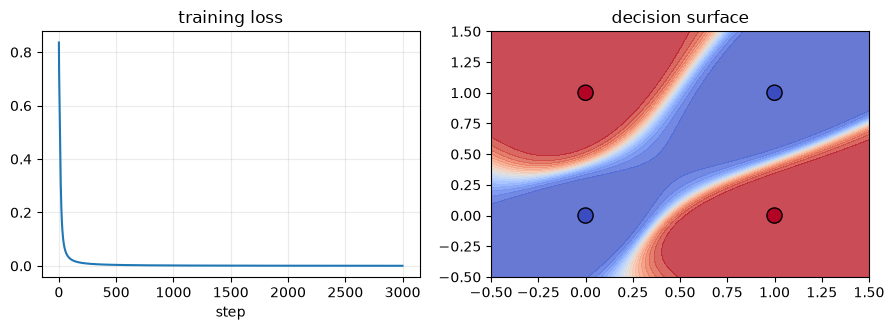

In [5]:
lr = 1.0
history = []
for step in range(3000):
    y_hat, cache = forward(params, X)
    history.append(bce_loss(y_hat, y))
    grads = backward(params, cache, y)
    for name in params:
        params[name] -= lr * grads[name]

final_pred, _ = forward(params, X)
print("最终 loss:", round(history[-1], 4))
print("预测概率:", np.round(final_pred[:, 0], 3), " 目标:", y[:, 0])
assert np.all((final_pred[:, 0] > 0.5) == (y[:, 0] == 1)), "网络应学会 XOR"

# 画出决策边界：线性模型做不到的“弯曲边界”
grid = np.linspace(-0.5, 1.5, 120)
gx, gy = np.meshgrid(grid, grid)
probs_grid = forward(params, np.c_[gx.ravel(), gy.ravel()])[0].reshape(gx.shape)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(history); axes[0].set_title("training loss"); axes[0].set_xlabel("step"); axes[0].grid(alpha=.25)
axes[1].contourf(gx, gy, probs_grid, levels=20, cmap="coolwarm", alpha=.8)
axes[1].scatter(X[:, 0], X[:, 1], c=y[:, 0], cmap="coolwarm", edgecolors="k", s=120)
axes[1].set_title("decision surface")
plt.tight_layout(); plt.show(); plt.close()


## 6. 和强化学习的连接：Q 网络就是“会泛化的 Q 表”

| | Q 表（Chapter05、GridWorld） | Q 网络（Chapter06 DQN） |
|---|---|---|
| 输入 | 状态编号 | 状态向量或图像 |
| 输出 | 查表得到每个动作的 Q 值 | 前向传播得到每个动作的 Q 值，shape `(B, n_actions)` |
| 更新 | 只改一个格子 | 梯度下降改所有参数，相似状态一起变 |
| 优点/风险 | 精确但无法处理大状态空间 | 能泛化，但训练可能不稳定（所以有 replay、target network） |

训练 Q 网络和本课一样：有输入、有“目标值”（来自 Bellman 方程）、有 loss、有梯度下降。
区别只是目标值不是人工标签，而是由奖励和网络自己的估计算出来——这正是 RL 训练不稳定的根源。

## 7. 常见误区

- **权重全部初始化为 0：**同一层所有神经元永远一样，网络学不到东西。
- **学习率越大越快：**太大会让 loss 震荡甚至变成 `nan`；可以把上面的 `lr` 改成 20 试试。
- **梯度 shape 对上了就一定对：**shape 只是必要条件，仍需梯度检查。
- **网络越大越好：**RL 中大网络更难训练，原书多数例子用两层几百个神经元的 MLP 就够了。


## 自动批改练习

每道题先读题、再写代码、最后运行同一格。看到 `[通过]` 才算完成；`[未通过]` 会说明哪里不对。
参考答案默认折叠，建议独立尝试至少 10 分钟后再看。


In [6]:
# 自动检查工具：每道练习末尾都会调用 check(test_xxx)。
# 未完成或有错时只打印提示，不会中断 Run All。
def check(test):
    try:
        test()
    except NotImplementedError:
        print(f"[未完成] {test.__name__}：把 raise NotImplementedError 换成你的代码，再运行本格。")
    except AssertionError as error:
        print(f"[未通过] {test.__name__}：{error}")
    except Exception as error:  # 代码本身报错，也给出可读提示
        print(f"[代码报错] {test.__name__}：{type(error).__name__}: {error}")
    else:
        print(f"[通过] {test.__name__}")


### 练习 1：ReLU 及其导数

实现 `relu(x)` 与 `relu_grad(x)`。约定 $x=0$ 处导数取 0。
两个函数都要支持任意 shape 的数组，并返回同 shape 的数组。

<details><summary>提示（卡住 10 分钟再看）</summary>

`np.maximum(x, 0)`；导数可写成 `(x > 0).astype(float)`。

</details>


In [7]:
import numpy as np

def relu(x):
    raise NotImplementedError

def relu_grad(x):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_relu():
    x = np.array([[-2.0, 0.0, 3.0]])
    assert np.allclose(relu(x), [[0.0, 0.0, 3.0]]), "负数应变成 0，正数保持不变"
    assert np.allclose(relu_grad(x), [[0.0, 0.0, 1.0]]), "导数：x>0 为 1，否则为 0"
    assert relu(x).shape == x.shape and relu_grad(x).shape == x.shape, "输出 shape 必须与输入相同"

check(test_relu)


[未完成] test_relu：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def relu(x):
    return np.maximum(x, 0.0)

def relu_grad(x):
    return (np.asarray(x) > 0).astype(float)
```

</details>


### 练习 2：线性层的前向传播与 shape

实现 `linear_forward(X, W, b)`，返回 $XW+b$。要求：如果 `X.shape[1] != W.shape[0]`，
抛出 `ValueError` 并在信息中写出两个 shape。养成“先检查 shape”的习惯，以后能省下大量调试时间。


In [8]:
import numpy as np

def linear_forward(X, W, b):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_linear_forward():
    X = np.ones((4, 3)); W = np.arange(6.0).reshape(3, 2); b = np.array([1.0, -1.0])
    out = linear_forward(X, W, b)
    assert out.shape == (4, 2), f"(4,3)@(3,2)+(2,) 应得 (4,2)，得到 {out.shape}"
    assert np.allclose(out[0], [7.0, 8.0]), f"第一行应为 [7, 8]，得到 {out[0]}"
    try:
        linear_forward(np.ones((4, 2)), W, b)
    except ValueError:
        pass
    else:
        raise AssertionError("shape 不匹配时应抛出 ValueError")

check(test_linear_forward)


[未完成] test_linear_forward：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def linear_forward(X, W, b):
    if X.shape[1] != W.shape[0]:
        raise ValueError(f"shape 不匹配: X{X.shape} 与 W{W.shape}")
    return X @ W + b
```

</details>


### 练习 3：数值稳定的 sigmoid 与二分类交叉熵

实现 `sigmoid(z)` 与 `bce(p, y)`。
- $\sigma(z)=1/(1+e^{-z})$，要求 `z=-1000` 和 `z=1000` 时不出现 `nan`/警告；
- $\mathrm{BCE}=-\frac1N\sum[y\log p+(1-y)\log(1-p)]$，计算前把 `p` 裁剪到 `[1e-7, 1-1e-7]`。

<details><summary>提示（卡住 10 分钟再看）</summary>

sigmoid 的稳定写法：`np.exp(-np.logaddexp(0, -z))`；或先 `np.clip(z, -500, 500)`。

</details>


In [9]:
import numpy as np

def sigmoid(z):
    raise NotImplementedError

def bce(p, y):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np
import warnings

def test_sigmoid_bce():
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        s = sigmoid(np.array([-1000.0, 0.0, 1000.0]))
    assert np.allclose(s, [0.0, 0.5, 1.0]), f"应约为 [0, 0.5, 1]，得到 {s}"
    assert abs(bce([0.9, 0.1], [1, 0]) - 0.1053605) < 1e-5, "两个都预测对且置信 0.9，BCE≈0.1054"
    assert np.isfinite(bce([0.0, 1.0], [1, 0])), "完全预测错也不能得到 inf，记得裁剪"

check(test_sigmoid_bce)


[未完成] test_sigmoid_bce：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def sigmoid(z):
    return np.exp(-np.logaddexp(0.0, -np.asarray(z, dtype=float)))

def bce(p, y):
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    y = np.asarray(y, dtype=float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
```

</details>


### 练习 4：数值梯度（梯度检查）

实现 `numerical_grad(f, x, eps=1e-5)`：对向量 `x` 的每一维用中心差分
$\frac{f(x+\epsilon e_i)-f(x-\epsilon e_i)}{2\epsilon}$ 估计偏导数，返回与 `x` 同 shape 的数组。
手写反向传播后，用它核对解析梯度——这是排查梯度 bug 最可靠的方法。

<details><summary>提示（卡住 10 分钟再看）</summary>

循环 `for i in range(x.size)`，每次复制 `x`，只改第 i 个元素。注意不要修改调用者传进来的 `x`。

</details>


In [10]:
import numpy as np

def numerical_grad(f, x, eps=1e-5):
    x = np.asarray(x, dtype=float)
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_numerical_grad():
    f = lambda v: float(np.sum(v ** 2) + 3 * v[0])
    x = np.array([1.0, -2.0, 0.5])
    g = numerical_grad(f, x)
    assert g.shape == x.shape, "梯度 shape 应与 x 相同"
    assert np.allclose(g, [5.0, -4.0, 1.0], atol=1e-4), f"解析梯度是 2x + [3,0,0] = [5,-4,1]，得到 {g}"
    assert np.allclose(x, [1.0, -2.0, 0.5]), "不要修改传入的 x"

check(test_numerical_grad)


[未完成] test_numerical_grad：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def numerical_grad(f, x, eps=1e-5):
    x = np.asarray(x, dtype=float)
    grad = np.zeros_like(x)
    flat = grad.reshape(-1)
    for i in range(x.size):
        plus = x.copy().reshape(-1); minus = x.copy().reshape(-1)
        plus[i] += eps; minus[i] -= eps
        flat[i] = (f(plus.reshape(x.shape)) - f(minus.reshape(x.shape))) / (2 * eps)
    return grad
```

</details>


### 练习 5：两层线性网络等于一层

没有激活函数时，$(XW_1+b_1)W_2+b_2$ 仍然是线性的。实现 `merge_linear(W1, b1, W2, b2)`，
返回等价的单层 `(W, b)`。做完这题，你就能用一句话解释“为什么神经网络需要非线性激活”。

<details><summary>提示（卡住 10 分钟再看）</summary>

展开：$XW_1W_2 + b_1W_2 + b_2$。

</details>


In [11]:
import numpy as np

def merge_linear(W1, b1, W2, b2):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_merge_linear():
    rng = np.random.default_rng(1)
    W1, b1 = rng.normal(size=(3, 5)), rng.normal(size=5)
    W2, b2 = rng.normal(size=(5, 2)), rng.normal(size=2)
    X = rng.normal(size=(7, 3))
    W, b = merge_linear(W1, b1, W2, b2)
    assert W.shape == (3, 2) and b.shape == (2,), f"W 应为 (3,2)，b 应为 (2,)，得到 {W.shape}, {b.shape}"
    assert np.allclose((X @ W1 + b1) @ W2 + b2, X @ W + b), "合并后的单层输出应与两层完全相同"

check(test_merge_linear)


[未完成] test_merge_linear：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def merge_linear(W1, b1, W2, b2):
    return W1 @ W2, b1 @ W2 + b2
```

</details>


## 过关标准

- [ ] 5 道练习全部 `[通过]`；
- [ ] 合上笔记，能在纸上写出 `2→8→1` 网络每一步的 shape 和七个梯度公式；
- [ ] 能解释“为什么需要非线性激活”和“为什么要做梯度检查”；
- [ ] 能用自己的话说出 Q 表与 Q 网络的区别。

**选读：**[3Blue1Brown 神经网络系列](https://www.3blue1brown.com/topics/neural-networks)（可视化直觉，强烈推荐先看前 4 集）；
[动手学深度学习 · 多层感知机](https://zh.d2l.ai/chapter_multilayer-perceptrons/index.html)。
